# ML 06 — Nonlinear tabular models: Random Forest and XGBoost

This notebook tests whether nonlinear tree ensembles improve on Ridge when predicting the scalar canopy-averaged wind-speed target from geometry summaries. Both models use the same family-held-out fold design and explicit feature set. Feature importance is treated as model-specific predictive attribution, not causality.

In [1]:
from pathlib import Path
import os

# Works whether Jupyter starts in the repository root or this notebook's folder.
_candidates = [Path.cwd(), *Path.cwd().parents]
ROOT = next((p for p in _candidates if (p / "data" / "raw").exists() and (p / "Machine Learning Pipeline").exists()), None)
if ROOT is None:
    raise FileNotFoundError("Could not find the repository root. Open this notebook from inside the T006 project folder.")
DATA_RAW = ROOT / "data" / "raw"
DATA_PROCESSED = ROOT / "data" / "processed"
RESULTS = ROOT / "results"
DATA_PROCESSED.mkdir(parents=True, exist_ok=True)
RESULTS.mkdir(parents=True, exist_ok=True)
print("Project root:", ROOT)

Project root: /Users/suhaanigarg/Desktop/T006-urban-microclimate-modelling


In [2]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

processed_path = DATA_PROCESSED / "feature_engineered_dataset.csv"
if not processed_path.exists():
    raise FileNotFoundError("Run ML_01, then ML_03 first; ML_03 builds the engineered modelling dataset from raw data.")
df = pd.read_csv(processed_path)
TARGET = "target_U_canopy_mean_m_s"
NUMERIC_FEATURES = ["plan_area_density", "plan_area_density_sq", "height_std_m", "height_max_m", "height_min_m", "height_range_m", "height_skew", "frac_taller_than_mean", "wind_direction_sin", "wind_direction_cos", "height_coefficient_variation"]
CATEGORICAL_FEATURES = ["configuration", "horizontal_configuration", "density_class"]
FEATURES = NUMERIC_FEATURES + CATEGORICAL_FEATURES
BASELINE_NUMERIC = ["plan_area_density", "height_std_m", "height_max_m", "building_count", "wind_direction_sin", "wind_direction_cos"]
BASELINE_FEATURES = BASELINE_NUMERIC + CATEGORICAL_FEATURES
print("Dataset shape:", df.shape)
print("Target:", TARGET)

Dataset shape: (224, 22)
Target: target_U_canopy_mean_m_s


## 1. Define comparable model pipelines

Random Forest averages predictions from many randomized trees; XGBoost adds trees sequentially to correct previous residuals. Both can capture nonlinear interactions that Ridge cannot represent directly. The settings below are fixed, reproducible baseline hyperparameters; this notebook does not claim an exhaustive hyperparameter search.

In [3]:
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GroupKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from xgboost import XGBRegressor

preprocessor = ColumnTransformer([
    ("numeric", SimpleImputer(strategy="median"), NUMERIC_FEATURES),
    ("categorical", Pipeline([("imputer", SimpleImputer(strategy="most_frequent")), ("onehot", OneHotEncoder(handle_unknown="ignore"))]), CATEGORICAL_FEATURES),
])

def make_tree_models():
    return {
        "Random Forest": Pipeline([("preprocess", preprocessor), ("model", RandomForestRegressor(n_estimators=300, min_samples_leaf=2, max_features=0.9, n_jobs=-1, random_state=42))]),
        "XGBoost": Pipeline([("preprocess", preprocessor), ("model", XGBRegressor(n_estimators=200, max_depth=2, learning_rate=0.03, min_child_weight=3, subsample=0.85, colsample_bytree=0.9, reg_lambda=2.0, objective="reg:squarederror", tree_method="hist", n_jobs=4, random_state=42))]),
    }

X = df[FEATURES]
y = df[TARGET]
groups = df["family_id"]
cv = GroupKFold(n_splits=5)

## 2. Train models and collect out-of-fold predictions

In [4]:
prediction_rows = []
fold_rows = []
importance_rows = []
for fold, (train_idx, test_idx) in enumerate(cv.split(X, y, groups), start=1):
    assert set(groups.iloc[train_idx]).isdisjoint(set(groups.iloc[test_idx]))
    for model_name, model in make_tree_models().items():
        model.fit(X.iloc[train_idx], y.iloc[train_idx])
        pred = model.predict(X.iloc[test_idx])
        actual = y.iloc[test_idx].to_numpy()
        fold_rows.append({"fold": fold, "model": model_name, "n_test_cases": len(test_idx),
                          "mae_m_s": mean_absolute_error(actual, pred),
                          "rmse_m_s": np.sqrt(mean_squared_error(actual, pred)),
                          "r2": r2_score(actual, pred)})
        for idx, obs, estimate in zip(test_idx, actual, pred):
            prediction_rows.append({"fold": fold, "simulation_id": df.iloc[idx].simulation_id,
                                    "layout_id": df.iloc[idx].layout_id, "family_id": df.iloc[idx].family_id,
                                    "wind_direction_deg": float(df.iloc[idx].wind_direction_deg),
                                    "observed": float(obs), "predicted": float(estimate), "model": model_name})
        fitted_pre = model.named_steps["preprocess"]
        fitted_tree = model.named_steps["model"]
        names = fitted_pre.get_feature_names_out()
        for feature_name, importance in zip(names, fitted_tree.feature_importances_):
            raw_name = feature_name.split("__", 1)[-1]
            original = next((c for c in CATEGORICAL_FEATURES if raw_name == c or raw_name.startswith(c + "_")), raw_name)
            importance_rows.append({"fold": fold, "model": model_name, "feature": original, "importance": float(importance)})

predictions_df = pd.DataFrame(prediction_rows)
fold_metrics = pd.DataFrame(fold_rows)
importance_df = pd.DataFrame(importance_rows)
display(fold_metrics.round(4))
assert predictions_df.groupby("model").simulation_id.nunique().eq(len(df)).all()

,fold,model,n_test_cases,mae_m_s,rmse_m_s,r2
0,1,Random Forest,56,0.2499,0.3857,0.9063
1,1,XGBoost,56,0.2362,0.3524,0.9218
2,2,Random Forest,42,0.1825,0.3187,0.7439
3,2,XGBoost,42,0.1605,0.2140,0.8845
4,3,Random Forest,42,0.2604,0.3837,0.8894
5,3,XGBoost,42,0.2647,0.3234,0.9214
6,4,Random Forest,42,0.2624,0.3695,0.6650
7,4,XGBoost,42,0.2372,0.3043,0.7727
8,5,Random Forest,42,0.3291,0.4310,0.7388
9,5,XGBoost,42,0.2620,0.3175,0.8583


## 3. Compare pooled predictions and inspect importance

,model,n_cases,mae_m_s,rmse_m_s,r2
1,XGBoost,224,0.2324,0.3091,0.9035
0,Random Forest,224,0.2564,0.3798,0.8542


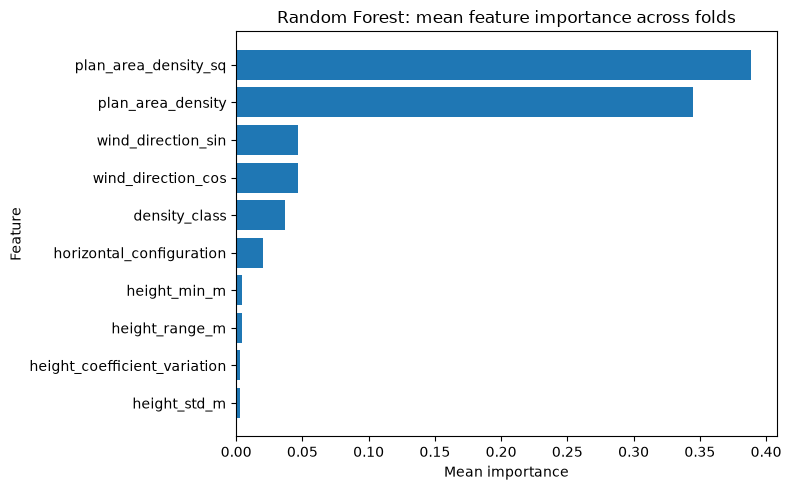

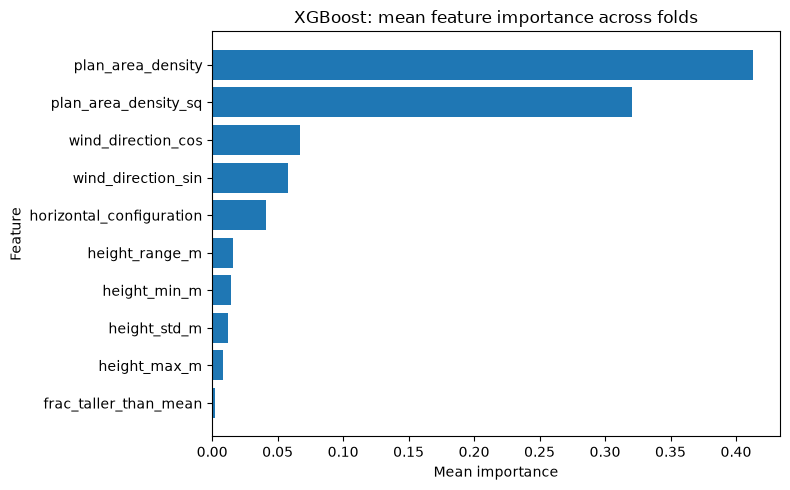

In [5]:
metric_rows = []
for model_name, group in predictions_df.groupby("model"):
    metric_rows.append({"model": model_name, "n_cases": len(group),
                        "mae_m_s": mean_absolute_error(group.observed, group.predicted),
                        "rmse_m_s": np.sqrt(mean_squared_error(group.observed, group.predicted)),
                        "r2": r2_score(group.observed, group.predicted)})
model_metrics = pd.DataFrame(metric_rows).sort_values("mae_m_s")
display(model_metrics.round(4))

mean_importance = importance_df.groupby(["model", "feature"], as_index=False).importance.mean()
for model_name in mean_importance.model.unique():
    top = mean_importance[mean_importance.model == model_name].sort_values("importance", ascending=False).head(10)
    fig, ax = plt.subplots(figsize=(8, 5))
    ax.barh(top.feature[::-1], top.importance[::-1])
    ax.set(title=f"{model_name}: mean feature importance across folds", xlabel="Mean importance", ylabel="Feature")
    plt.tight_layout()
    plt.show()

## 4. Compare error patterns, not only aggregate scores

Aggregate MAE/RMSE can hide systematic errors. The plots below compare observed versus out-of-fold predictions and absolute error by wind direction. A good aggregate score does not guarantee every family or direction is predicted equally well.

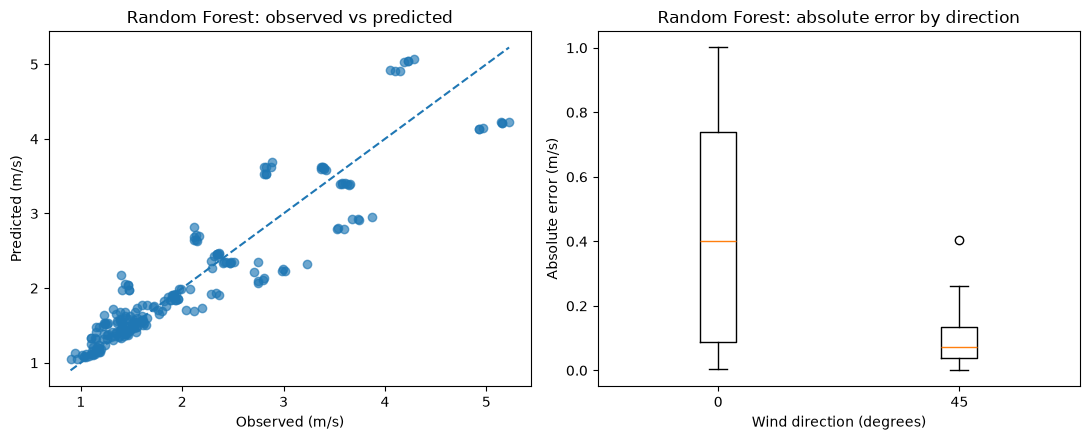

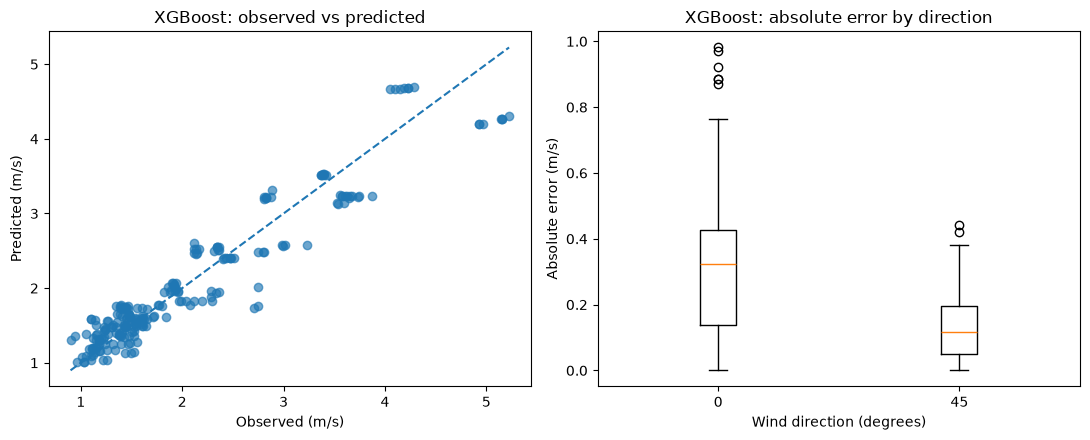

Mean feature importance across folds (descriptive, not causal):


,model,feature,importance
11,Random Forest,plan_area_density_sq,0.388709
10,Random Forest,plan_area_density,0.344656
13,Random Forest,wind_direction_sin,0.046914
12,Random Forest,wind_direction_cos,0.046905
1,Random Forest,density_class,0.037209
9,Random Forest,horizontal_configuration,0.020458
5,Random Forest,height_min_m,0.004399
6,Random Forest,height_range_m,0.004133
3,Random Forest,height_coefficient_variation,0.002933
8,Random Forest,height_std_m,0.002694


In [7]:
for model_name in sorted(predictions_df.model.unique()):
    part = predictions_df[predictions_df.model == model_name]
    fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
    axes[0].scatter(part.observed, part.predicted, alpha=.65)
    lo = min(part.observed.min(), part.predicted.min()); hi = max(part.observed.max(), part.predicted.max())
    axes[0].plot([lo, hi], [lo, hi], linestyle="--")
    axes[0].set(title=f"{model_name}: observed vs predicted", xlabel="Observed (m/s)", ylabel="Predicted (m/s)")
    part = part.copy(); part["absolute_error"] = (part.observed - part.predicted).abs()
    directions = sorted(part.wind_direction_deg.unique())
    axes[1].boxplot(
    [part.loc[part.wind_direction_deg == d, "absolute_error"] for d in directions],
    tick_labels=[str(int(d)) for d in directions]
)
    axes[1].set(title=f"{model_name}: absolute error by direction", xlabel="Wind direction (degrees)", ylabel="Absolute error (m/s)")
    plt.tight_layout(); plt.show()

if not importance_df.empty:
    print("Mean feature importance across folds (descriptive, not causal):")
    display(importance_df.groupby(["model", "feature"], as_index=False).importance.mean().sort_values(["model", "importance"], ascending=[True, False]).groupby("model").head(10))

## 4. Save outputs from this run

In [8]:
fold_metrics.to_csv(RESULTS / "tree_fold_metrics.csv", index=False)
predictions_df.to_csv(RESULTS / "tree_oof_predictions.csv", index=False)
model_metrics.to_csv(RESULTS / "tree_model_metrics.csv", index=False)
importance_df.to_csv(RESULTS / "tree_feature_importance_by_fold.csv", index=False)
mean_importance.to_csv(RESULTS / "tree_feature_importance.csv", index=False)
print("Fresh tree-model outputs saved in:", RESULTS)

Fresh tree-model outputs saved in: /Users/suhaanigarg/Desktop/T006-urban-microclimate-modelling/results
